# Chapitre 10 - Cours 4 : au-delà de MapReduce, moteurs dataflow et langages de requête

MapReduce matérialise tout, trie entre chaque étape et attend la dernière tâche avant de
continuer. Les **moteurs dataflow** (Spark, Flink, Tez) traitent un workflow entier
comme un seul job, enchaînent les opérateurs sans tout écrire sur disque, et retrouvent
la tolérance aux pannes par **recalcul**. Par-dessus, les **langages de haut niveau**
(SQL) laissent un optimiseur choisir comment exécuter. Ce cours couvre
la section *Beyond MapReduce* (*Materialization of Intermediate State*, *Graphs and Iterative Processing*, *High-Level APIs and Languages*).

**Plan.**

1. Matérialiser l'état intermédiaire, ou le faire circuler.
2. Un moteur dataflow miniature : DAG d'opérateurs et fusion.
3. Tolérance aux pannes : lignage, recalcul et déterminisme.
4. Graphes et traitement itératif : le modèle Pregel.
5. Langages de haut niveau et optimiseurs.


In [1]:
import json
import math
import os
import sqlite3
import subprocess
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import batch as B
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, COLORS, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 3)
lines = B.generate_access_log(120_000, n_urls=1500, seed=3)
shards = [lines[i::6] for i in range(6)]

## 1. Matérialiser l'état intermédiaire, ou le faire circuler (section *Materialization of Intermediate State*)

Dans une chaîne de jobs MapReduce, la sortie de chaque job est **matérialisée** : écrite
entièrement dans le DFS, répliquée, puis relue par le job suivant. C'est utile quand
cette sortie est un jeu de données publié, que d'autres équipes réutilisent. Mais le plus
souvent, ce n'est qu'un **état intermédiaire**, qui ne sert qu'au job suivant. Le livre
relève trois défauts de cette matérialisation systématique :

- un job ne peut démarrer que lorsque **toutes** les tâches du job précédent sont
  finies : une seule tâche à la traîne retarde tout le workflow ;
- les mappeurs du job suivant ne font souvent que relire ce que le réducteur précédent
  vient d'écrire : ils pourraient être fusionnés avec lui ;
- l'état intermédiaire est **répliqué** sur plusieurs machines, ce qui est excessif
  pour une donnée temporaire.

Les tuyaux Unix, au contraire, font **circuler** les données (cours 1, section 5) : chaque
étage commence dès que les premières lignes arrivent. Simulons un workflow de 4 étapes
sur 50 partitions, avec des durées de tâches aléatoires (et quelques tâches à la
traîne), exécuté avec barrières (MapReduce) ou en pipeline (chaque partition enchaîne les
étapes dès que son entrée est prête, comme dans un moteur dataflow pour des opérateurs
qui ne changent pas le partitionnement).

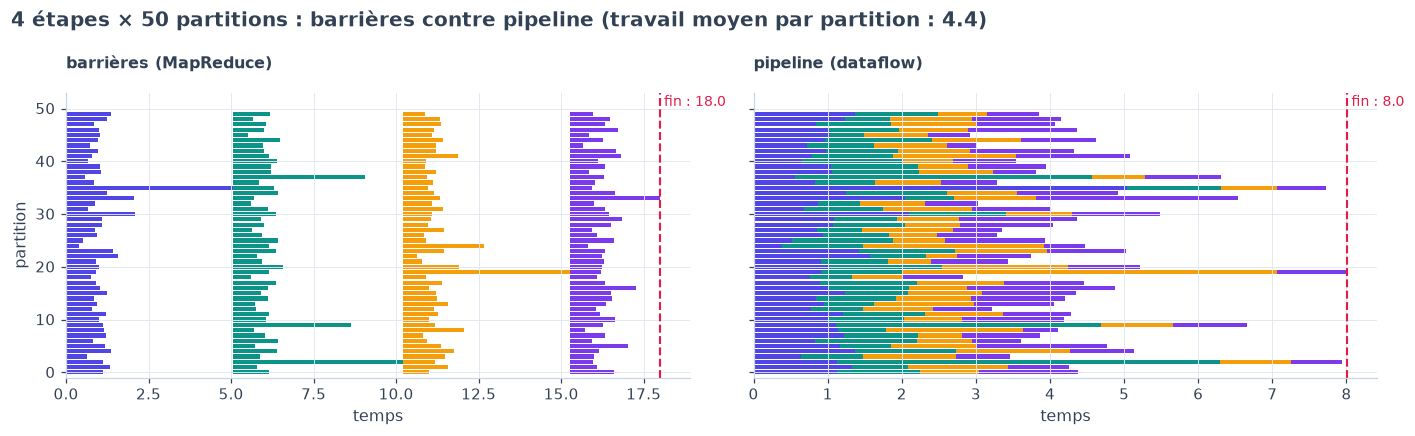

In [2]:
rng = np.random.default_rng(1)
P, K = 50, 4
dur = rng.lognormal(0, 0.35, size=(K, P))
dur[rng.random((K, P)) < 0.03] *= 4                          # quelques tâches à la traîne
barriere = dur.max(axis=1).sum()                             # chaque étape attend la plus lente
pipeline = dur.sum(axis=0).max()                             # chaque partition va à son rythme
ideal = dur.sum() / P
fig, axes = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for ax, mode in zip(axes, ["barrières (MapReduce)", "pipeline (dataflow)"]):
    for p in range(P):
        t = 0.0
        for k in range(K):
            start = dur[:k].max(axis=1).sum() if mode.startswith("barr") else t
            ax.barh(p, dur[k, p], left=start, color=[INDIGO, TEAL, AMBER, VIOLET][k], height=0.8)
            t = start + dur[k, p]
    fin = barriere if mode.startswith("barr") else pipeline
    ax.axvline(fin, color=ROSE, ls="--", lw=1.4)
    ax.text(fin, P + 0.5, f" fin : {fin:.1f}", color=ROSE, fontsize=9)
    ax.set_title(mode, fontsize=10.5); ax.set_xlabel("temps")
axes[0].set_ylabel("partition"); axes[0].set_ylim(-1, P + 3)
finish(fig, f"4 étapes × 50 partitions : barrières contre pipeline (travail moyen par partition : {ideal:.1f})")
plt.show()

Avec barrières, chaque étape coûte la durée de sa tâche la plus lente : les traînards de
chaque étape s'additionnent. En pipeline, une partition lente ne retarde qu'elle-même.
Ce gain n'existe que pour les opérateurs qui ne mélangent pas les partitions : un
opérateur qui trie ou regroupe (un shuffle) doit attendre **toute** son entrée, car le
dernier enregistrement lu peut être le plus petit.

> **À retenir.** Matérialiser chaque état intermédiaire impose des barrières entre jobs,
> des écritures répliquées et des relectures inutiles. Faire circuler les données entre
> opérateurs supprime ces coûts, sauf aux opérateurs qui ont besoin de toute leur entrée
> (tri, regroupement).